# 07c. Case study: the January 2012 Pacific Northwest storm: event maps

Event-total precipitation (GPCP) and the event-mean 2-m temperature anomaly (vs the observed or the AMIP climatology) on `event_window`, observations against the ensemble-and-start mean of every configuration. Design and event definition: `07a`.

**The 07a-07d series** (January 2012 Pacific Northwest storm; each notebook reads the data it needs, computes, saves, then plots): `07a` regional series; `07b` member storm metrics; `07c` event maps; `07d` storm environment. Settings: `WinterStormSettings` in `configs/hind_lead_eval_cases.py`; products: `util/winter_storm_workflow.py`; methods: `util/winter_storm_case.py`. Design and event definition: `07a`.

Every product is saved with the settings it was computed from and read back on the next run when those settings are unchanged; `FORCE_COMPUTE = True` recomputes this notebook's results, `FORCE_INPUTS = True` also re-reads the model output and observations. Model output is read only when a product has to be (re)computed.

## Outputs

`data/hind_lead_eval/winter_storm_2012/storm_event_maps.nc`; figures `storm_map_precip.png`, `storm_map_t2m_<BIAS>.png`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options; plain values only, so `papermill -p` overrides work. Case definitions (experiments, regions, windows, options) are the settings defaults; change them for this notebook with `CASE_OVERRIDES`.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"           # land fraction
AMIP_ROOT = OBSERVATION_ROOT / "E3SMv3"                        # free-running E3SMv3 DECK AMIP runs
WORKFLOW_NAME = "hind_lead_eval"

CONFIGS = {   # configuration key: raw case name (one case per start: INPUT_DATA_ROOT/<case name>_<YYYYMMDD>00/<ENxx>)
    "CLIM_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE",
    "HYB_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE",
    "DA_COUPLED": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED",
    "DA_ATM": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM",
    "DA_LND": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND",
}
# the experiments analysed are the keys of CONFIGS, in this order (tables and legends)

CASE_OVERRIDES = {}     # changes to the WinterStormSettings defaults (configs/hind_lead_eval_cases.py), e.g. {"max_members": 4}
FORCE_COMPUTE = False    # recompute this notebook's results even when they are saved with the same settings
FORCE_INPUTS = False     # also re-read the model output and observations (slow)


## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.fcst_init_experiment_config import STYLE_MAP, set_case_names
from configs.hind_lead_eval_cases import WinterStormSettings, RunPaths
from util.hind_case_io import figure_saver, write_dataset, write_table
from util.winter_storm_workflow import WinterStormCase

paths = RunPaths(*(Path(p) for p in (INPUT_DATA_ROOT, WORK_DIR, DIAGNOSTIC_OUTPUT_ROOT, OBSERVATION_ROOT,
                                     LAND_SUPPORT_DIR, AMIP_ROOT)), workflow_name=WORKFLOW_NAME)
set_case_names(CONFIGS)   # the readers find each configuration's cases by these names
for c, name in CONFIGS.items():
    print(f"[CASE] {c}: {name}_<YYYYMMDD>00")
case = WinterStormCase(WinterStormSettings(paths=paths, **{"configs": tuple(CONFIGS), **CASE_OVERRIDES}), force_compute=FORCE_COMPUTE,
                   force_inputs=FORCE_INPUTS)
cfg = case.cfg


[CASE] CLIM_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE_<YYYYMMDD>00
[CASE] HYB_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE_<YYYYMMDD>00
[CASE] DA_COUPLED: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED_<YYYYMMDD>00
[CASE] DA_ATM: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM_<YYYYMMDD>00
[CASE] DA_LND: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND_<YYYYMMDD>00
[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/winter_storm_2012
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/winter_storm_2012
[IC DEFECT] ['HYB_BASE', 'DA_LND']


## 4. Read input

ERA5 daily-mean TREFHT and GPCP precipitation on the map box, both TREFHT climatologies (for the `amip` bias treatment and the temperature anomaly maps) and the regional masks (`observed_fields.nc`); the observed metrics and the simulation coverage of the window. The member fields are read only when `storm_event_maps.nc` must be recomputed.

In [4]:
obs = case.obs
display(obs.metrics.round(2), obs.coverage)

[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/winter_storm_2012/observed_fields.nc
{'WEST_WA_OR': 24, 'INLAND_PNW': 77} land points
[EVENT] 2012-01-16 to 2012-01-20; observed WEST_WA_OR precipitation peak 2012-01-19


,event_precip_mm,max_daily_precip_mm,peak_precip_date_error_days,event_mean_t_c,event_min_t_c,precip_freezing_days_mm,precip_near_freezing_days_mm,window_days_covered
region,,,,,,,,
WEST_WA_OR,97.89,48.14,0,0.26,-3.34,3.12,31.10,5
INLAND_PNW,21.72,10.43,2,-6.36,-9.64,21.72,21.72,5


,init,last_day,lead_at_onset,lead_at_end,window_covered
0,2011-12-16,2012-02-14,32,36,full
1,2011-12-21,2012-02-19,27,31,full
2,2011-12-26,2012-02-24,22,26,full
3,2011-12-31,2012-02-29,17,21,full


## 5. Process and save

Observed and ensemble-and-start-mean event maps of every configuration (`storm_event_maps.nc`).

In [5]:
maps = case.event_maps()
print(dict(maps.sizes))

[STALE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/winter_storm_2012/storm_event_maps.nc: built with other settings, recomputing
[MODEL] CLIM_BASE PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}
[MODEL] HYB_BASE PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}
[MODEL] DA_COUPLED PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}


[MODEL] DA_ATM PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}


[MODEL] DA_LND PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}
[MODEL] CLIM_BASE TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}


[MODEL] HYB_BASE TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}


[MODEL] DA_COUPLED TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}
[MODEL] DA_ATM TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}


[MODEL] DA_LND TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 14, 'lon': 24}


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/winter_storm_2012/storm_event_maps.nc
{'lat': 14, 'lon': 24, 'config': 5}


## 6. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/winter_storm_2012/storm_map_precip.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/winter_storm_2012/storm_map_t2m_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/winter_storm_2012/storm_map_t2m_amip.png


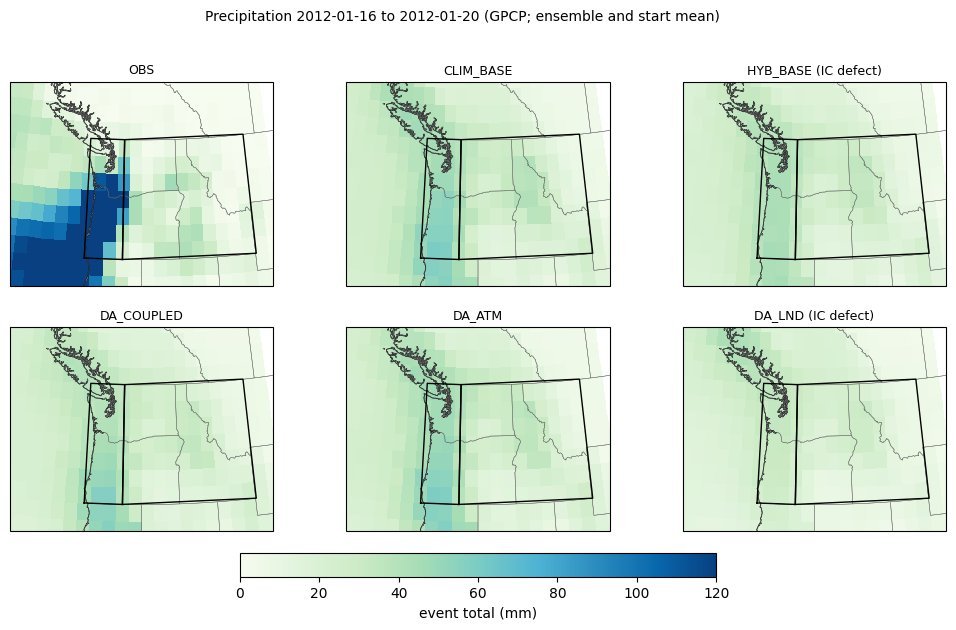

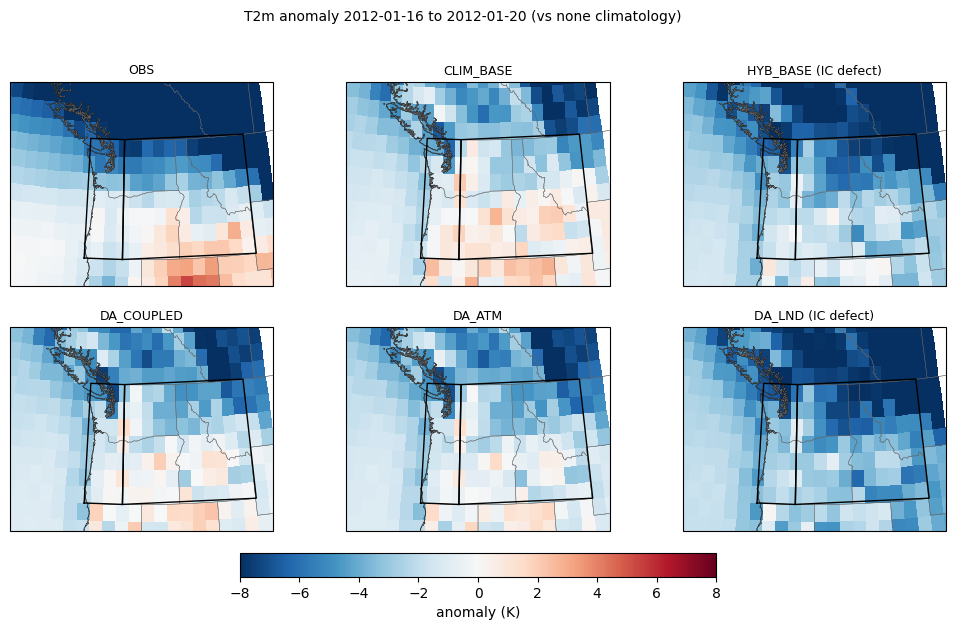

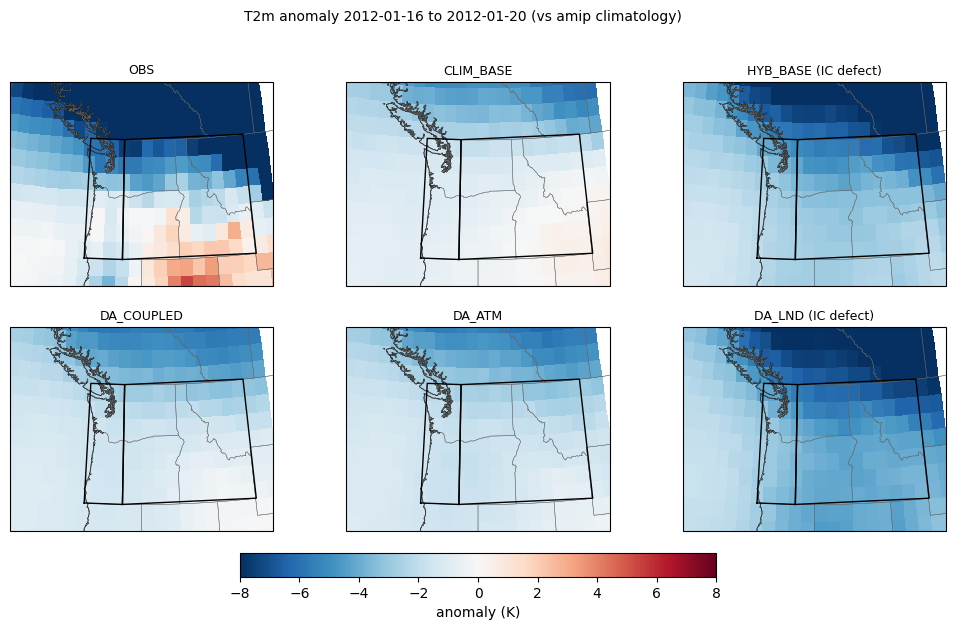

In [6]:
# ============================ Figure settings: edit here and rerun this cell ============================
SHOW = True          # False: save the figures without showing them
FIGURE_DPI = 200
FONT_SIZE = 18       # base font size (pt); every label of every figure scales with it
FONT_SCALES = dict(label=1.0, title=1.0, tick=0.9, legend=1.0, suptitle=1.15, cell=0.75)  # x FONT_SIZE

from util.fcst_init_plotting import set_font_size
set_font_size(FONT_SIZE, **FONT_SCALES)
save = figure_saver(case.figure_dir, dpi=FIGURE_DPI, show=SHOW)
# =========================================================================================================

from util.winter_storm_case import plot_event_maps

configs = list(cfg.configs)
w0, w1 = cfg.event_window
save(plot_event_maps(maps.obs_precip, {c: maps.precip.sel(config=c, drop=True) for c in configs}, list(cfg.regions),
                     list(cfg.ic_defect), cmap="GnBu", vmin=0, vmax=120, units="event total (mm)", extent=cfg.map_extent,
                     title=f"Precipitation {w0} to {w1} (GPCP; ensemble and start mean)"),
     "storm_map_precip.png")
for b in cfg.biases:
    save(plot_event_maps(maps.obs_t2m_anom, {c: maps[f"t2m_anom_{b}"].sel(config=c, drop=True) for c in configs},
                         list(cfg.regions), list(cfg.ic_defect), cmap="RdBu_r", vmin=-8, vmax=8, units="anomaly (K)",
                         extent=cfg.map_extent, title=f"T2m anomaly {w0} to {w1} (vs {b} climatology)"),
         f"storm_map_t2m_{b}.png")